In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


## Crop filtering for PPS

In [2]:
file='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/0.1x0.1gridded/03-07_0.1x0.1gridded_centrally_midwest_precip.parquet'
precip= pd.read_parquet(file, engine='pyarrow')

In [3]:
precip

,grid_lat,grid_lon,date,hour,h_precip_mm
0,37.05,-103.95,2024-03-01,2024-03-01 00:00:00,0.000
1,37.05,-103.95,2024-03-01,2024-03-01 01:00:00,0.000
2,37.05,-103.95,2024-03-01,2024-03-01 02:00:00,0.000
3,37.05,-103.95,2024-03-01,2024-03-01 03:00:00,0.000
4,37.05,-103.95,2024-03-01,2024-03-01 04:00:00,0.000
...,...,...,...,...,...
101517056,48.95,-80.05,2024-07-31,2024-07-31 19:00:00,0.000
101517057,48.95,-80.05,2024-07-31,2024-07-31 20:00:00,0.000
101517058,48.95,-80.05,2024-07-31,2024-07-31 21:00:00,0.000
101517059,48.95,-80.05,2024-07-31,2024-07-31 22:00:00,0.115


In [7]:
precip['h_precip_mm'].describe()

count    1.015171e+08
mean     2.573030e-01
std      1.240674e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      5.000000e-03
max      5.412500e+01
Name: h_precip_mm, dtype: float64

In [8]:
precip['date'].unique()

array([datetime.date(2024, 3, 1), datetime.date(2024, 3, 2),
       datetime.date(2024, 3, 3), datetime.date(2024, 3, 4),
       datetime.date(2024, 3, 5), datetime.date(2024, 3, 6),
       datetime.date(2024, 3, 7), datetime.date(2024, 3, 8),
       datetime.date(2024, 3, 9), datetime.date(2024, 3, 10),
       datetime.date(2024, 3, 11), datetime.date(2024, 3, 12),
       datetime.date(2024, 3, 13), datetime.date(2024, 3, 14),
       datetime.date(2024, 3, 15), datetime.date(2024, 3, 16),
       datetime.date(2024, 3, 17), datetime.date(2024, 3, 18),
       datetime.date(2024, 3, 19), datetime.date(2024, 3, 20),
       datetime.date(2024, 3, 21), datetime.date(2024, 3, 22),
       datetime.date(2024, 3, 23), datetime.date(2024, 3, 24),
       datetime.date(2024, 3, 25), datetime.date(2024, 3, 26),
       datetime.date(2024, 3, 27), datetime.date(2024, 3, 28),
       datetime.date(2024, 3, 29), datetime.date(2024, 3, 30),
       datetime.date(2024, 3, 31), datetime.date(2024, 4, 1),
  

In [9]:
crop_mask = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/0.1x0.1gridded/0.1x0.1_cropland_mask.parquet'
crop_df= pd.read_parquet(crop_mask, engine='pyarrow')

In [10]:
crop_df

,grid_lat,grid_lon,is_majority_cropland
16,35.95,-102.45,True
17,35.95,-102.35,True
19,35.95,-102.15,True
20,35.95,-102.05,True
21,35.95,-101.95,True
...,...,...,...
31398,48.95,-97.25,True
31399,48.95,-97.15,True
31400,48.95,-97.05,True
31401,48.95,-96.95,True


In [11]:
cropland_only = crop_df[crop_df['is_majority_cropland'] == True]

In [12]:
precip['date'] = pd.to_datetime(precip['date'], errors='coerce')

may_coords = (precip.loc[precip['date'].dt.month == 5, ['grid_lat', 'grid_lon']].drop_duplicates())

crop_coords = cropland_only[['grid_lat', 'grid_lon']].drop_duplicates()

missing = may_coords.merge(crop_coords, on=['grid_lat','grid_lon'], how='left', indicator=True)
missing_coords = missing[missing['_merge'] == 'left_only']
print(missing_coords.head())
print(f"Missing May coord pairs: {len(missing_coords)}")


   grid_lat  grid_lon     _merge
0     37.05   -103.95  left_only
1     37.05   -103.85  left_only
2     37.05   -103.75  left_only
3     37.05   -103.65  left_only
4     37.05   -103.55  left_only
Missing May coord pairs: 19687


In [13]:
precip['grid_lat'] = precip['grid_lat'].round(2)  
precip['grid_lon'] = precip['grid_lon'].round(2)

crop_df['grid_lat'] = crop_df['grid_lat'].round(2)
crop_df['grid_lon'] = crop_df['grid_lon'].round(2)

#merge w precip to keep only cropland precip
precip_cropland = pd.merge(precip, crop_df[crop_df['is_majority_cropland']][['grid_lat', 'grid_lon']], 
                           on=['grid_lat', 'grid_lon'], how='inner')

In [14]:
print(list(precip_cropland['date'].unique()))


[Timestamp('2024-03-01 00:00:00'), Timestamp('2024-03-02 00:00:00'), Timestamp('2024-03-03 00:00:00'), Timestamp('2024-03-04 00:00:00'), Timestamp('2024-03-05 00:00:00'), Timestamp('2024-03-06 00:00:00'), Timestamp('2024-03-07 00:00:00'), Timestamp('2024-03-08 00:00:00'), Timestamp('2024-03-09 00:00:00'), Timestamp('2024-03-10 00:00:00'), Timestamp('2024-03-11 00:00:00'), Timestamp('2024-03-12 00:00:00'), Timestamp('2024-03-13 00:00:00'), Timestamp('2024-03-14 00:00:00'), Timestamp('2024-03-15 00:00:00'), Timestamp('2024-03-16 00:00:00'), Timestamp('2024-03-17 00:00:00'), Timestamp('2024-03-18 00:00:00'), Timestamp('2024-03-19 00:00:00'), Timestamp('2024-03-20 00:00:00'), Timestamp('2024-03-21 00:00:00'), Timestamp('2024-03-22 00:00:00'), Timestamp('2024-03-23 00:00:00'), Timestamp('2024-03-24 00:00:00'), Timestamp('2024-03-25 00:00:00'), Timestamp('2024-03-26 00:00:00'), Timestamp('2024-03-27 00:00:00'), Timestamp('2024-03-28 00:00:00'), Timestamp('2024-03-29 00:00:00'), Timestamp('20

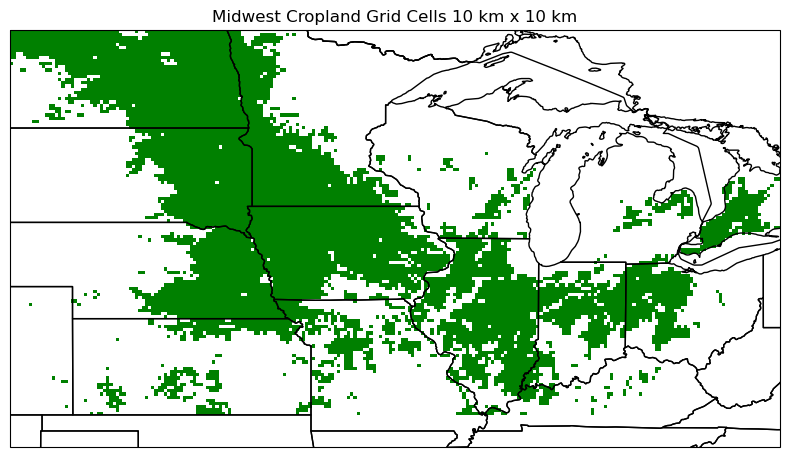

In [16]:
cropland_points = precip_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('Midwest Cropland Grid Cells 10 km x 10 km')
plt.tight_layout()
plt.savefig('/global/home/users/toireasamarie/Group_Meeting_Plots/11_19_25/Midwest_Cropland_10x10km.png', dpi=300)
plt.show()


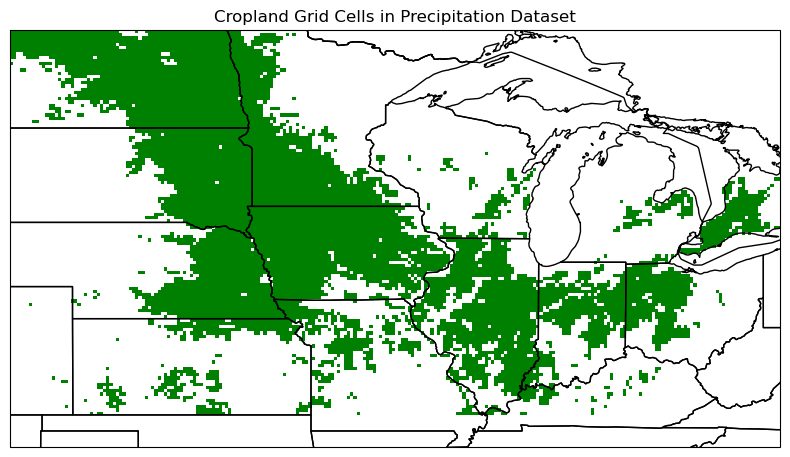

In [17]:
cropland_points = precip_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('Cropland Grid Cells in Precipitation Dataset')
plt.tight_layout()
plt.show()

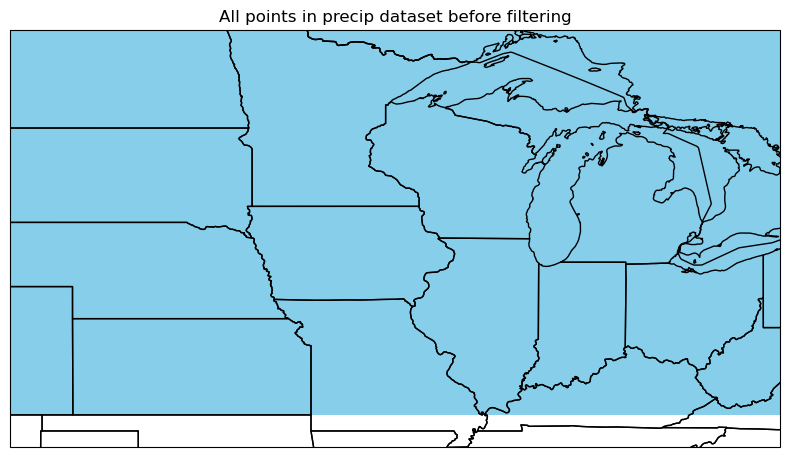

In [18]:
precip_points = precip[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in precip_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='skyblue',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('All points in precip dataset before filtering')
plt.tight_layout()
plt.show()

In [19]:
precip_cropland

,grid_lat,grid_lon,date,hour,h_precip_mm
0,37.05,-101.45,2024-03-01,2024-03-01 00:00:00,0.000
1,37.05,-101.45,2024-03-01,2024-03-01 01:00:00,0.000
2,37.05,-101.45,2024-03-01,2024-03-01 02:00:00,0.000
3,37.05,-101.45,2024-03-01,2024-03-01 03:00:00,0.000
4,37.05,-101.45,2024-03-01,2024-03-01 04:00:00,0.000
...,...,...,...,...,...
32374326,48.95,-96.85,2024-07-31,2024-07-31 19:00:00,0.345
32374327,48.95,-96.85,2024-07-31,2024-07-31 20:00:00,0.050
32374328,48.95,-96.85,2024-07-31,2024-07-31 21:00:00,0.000
32374329,48.95,-96.85,2024-07-31,2024-07-31 22:00:00,0.000


In [20]:
output = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/PPS_03-07_0.1x0.1gridded_cropfiltered.parquet'
precip_cropland.to_parquet(output, engine='pyarrow')

## Crop filtering for SMAP 


In [18]:
smap_file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/0.1x0.1gridded/SMAP_LAI_WFPS_0.1x0.1gridded_mar-jul.parquet'
smap_df = pd.read_parquet(smap_file, engine='pyarrow')

In [19]:
smap_df

,datetime,lat,lon,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,2024-02-29 22:28:55,36.05,-103.95,0.114719,209.289124,204.827133,0.133121,0.305608,0.272029
1,2024-02-29 22:28:55,36.05,-103.85,0.136838,209.268600,204.792053,0.131916,0.322000,0.308128
2,2024-02-29 22:28:55,36.05,-103.75,0.119576,209.228104,204.874603,0.145216,0.308726,0.280935
3,2024-02-29 22:28:55,36.05,-103.65,0.106267,209.052612,204.841431,0.156914,0.303328,0.254167
4,2024-02-29 22:28:55,36.05,-103.55,0.092758,208.658096,204.652618,0.149581,0.297745,0.226232
...,...,...,...,...,...,...,...,...,...
38219995,2024-07-31 22:28:55,48.95,-80.45,0.312607,299.696136,297.286926,3.231004,0.545900,0.572645
38219996,2024-07-31 22:28:55,48.95,-80.35,0.160308,300.061981,297.882446,3.293951,0.401898,0.386233
38219997,2024-07-31 22:28:55,48.95,-80.25,0.123584,300.108307,297.992554,3.220209,0.374100,0.330351
38219998,2024-07-31 22:28:55,48.95,-80.15,0.115252,300.174438,297.945709,3.664636,0.374100,0.308078


In [20]:
smap_df=smap_df.rename(columns={'lat':'grid_lat', 'lon':'grid_lon'})

In [21]:
grid_lon_sorted = np.sort(smap_df['grid_lon'].unique())
grid_lon_diff = np.diff(grid_lon_sorted)
print(np.unique(np.round(grid_lon_diff, 4)))


[0.1]


In [24]:
#need to round lat/lon to match cropland because likely has floating vals
smap_df['grid_lat'] =smap_df['grid_lat'].round(2)
smap_df['grid_lon'] =smap_df['grid_lon'].round(2)
cropland_only['grid_lat']=cropland_only['grid_lat'].round(2)
cropland_only['grid_lon']=cropland_only['grid_lon'].round(2)

In [25]:
#merge smap with cropland_only to get tempo crop points only 
smap_cropland = pd.merge(smap_df, cropland_only[['grid_lat', 'grid_lon']], on=['grid_lat', 'grid_lon'],how='inner')

In [27]:
grid_lon_sorted = np.sort(smap_cropland['grid_lon'].unique())
grid_lon_diff = np.diff(grid_lon_sorted)
print(np.unique(np.round(grid_lon_diff, 4)))


[0.1]


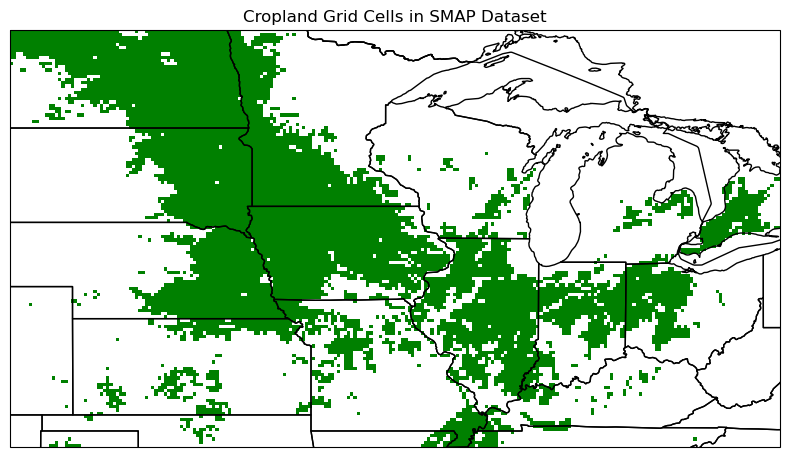

In [31]:
cropland_points = smap_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree())
    ax.add_patch(rect)

plt.title('Cropland Grid Cells in SMAP Dataset')
plt.tight_layout()
plt.show()

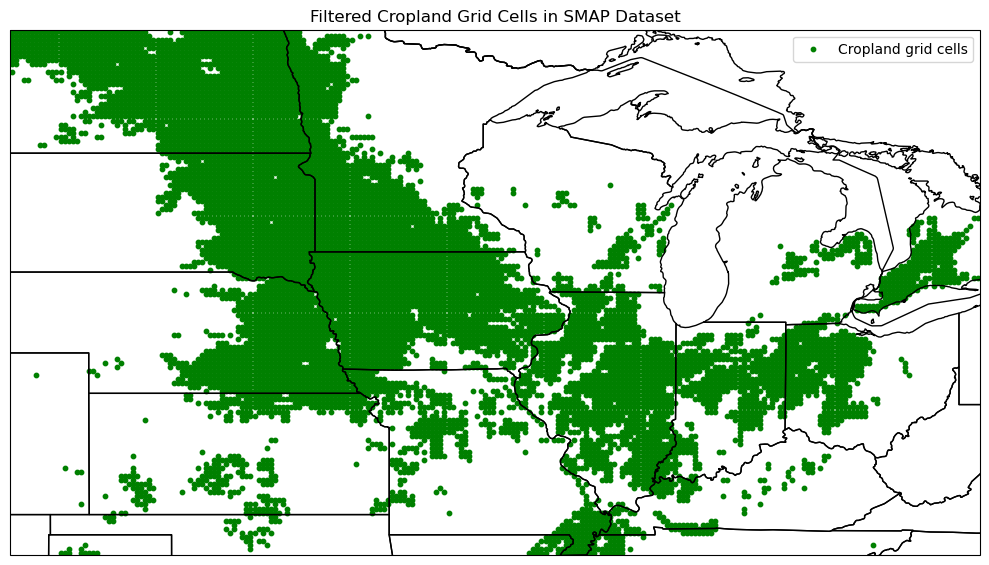

In [32]:
cropland_points = smap_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)

sc = ax.scatter(cropland_points['grid_lon'],cropland_points['grid_lat'],color='green',s=10,transform=ccrs.PlateCarree(),
                label='Cropland grid cells')

ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

plt.title('Filtered Cropland Grid Cells in SMAP Dataset')
plt.legend()
plt.tight_layout()
plt.show()

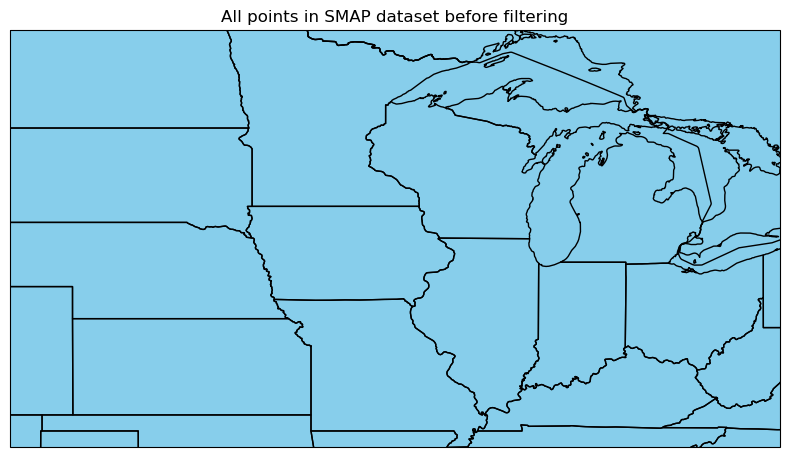

In [33]:
smap_points = smap_df[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in smap_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='skyblue',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('All points in SMAP dataset before filtering')
plt.tight_layout()
plt.show()

In [34]:
output = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/SMAP_03-07_0.1x0.1gridded_cropfiltered.parquet'
smap_cropland.to_parquet(output, engine='pyarrow')